# Overall sentiment model: grouped training and evaluation

This notebook explores the supplied review sample, uses the shared lowercasing/URL/whitespace cleaner, and trains the TF-IDF + Logistic Regression pipeline. Rating-derived dataset labels are proxy labels, not human annotations. Product IDs are kept disjoint between training and the held-out test split. Vectorization is fitted inside each cross-validation pipeline. Model selection uses grouped training-fold macro F1; the held-out test split is evaluated only after selection. The serialized pipeline is consumed by `inference.py` and `app.py`.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


Matplotlib is building the font cache; this may take a moment.


In [2]:
df = pd.read_csv("consumer_tech_reviews_9000.csv")

df.head()

,review_id,review_text,rating,sentiment,label_method,review_date,date_precision,product_id,product_name,category_hint,category_method,platform,source_url,source_dataset,source_row
0,4eca4d93ea0195c7585b,I hope I never drop this drive. I have a 1tb U...,4,positive,rating_proxy_1_2_negative_3_neutral_4_5_positive,2022,year_only_rounded_source_timestamp,B09HLCMJZQ,NaN,storage,keyword_mention_not_verified_product_category,Amazon,https://www.amazon.com/dp/B093275Z7V,https://huggingface.co/datasets/stephaniestv/E...,129228
1,d7e323b1d19bdd0f152c,The power output is as described. Plenty of po...,3,neutral,rating_proxy_1_2_negative_3_neutral_4_5_positive,2020,year_only_rounded_source_timestamp,B07N8KKR6X,NaN,audio,keyword_mention_not_verified_product_category,Amazon,https://www.amazon.com/dp/B07N8KKR6X,https://huggingface.co/datasets/stephaniestv/E...,143911
2,5cab98168e0087ac3e16,I currently own this Olympus E-M1 Mark III whi...,5,positive,rating_proxy_1_2_negative_3_neutral_4_5_positive,2021,year_only_rounded_source_timestamp,B08N69BP74,NaN,cameras,keyword_mention_not_verified_product_category,Amazon,https://www.amazon.com/dp/B083Y46RHQ,https://huggingface.co/datasets/stephaniestv/E...,171382
3,737aae8afee627ca9381,Upgraded from an X800G to this and right away ...,1,negative,rating_proxy_1_2_negative_3_neutral_4_5_positive,2021,year_only_rounded_source_timestamp,B08Z31SKBB,NaN,gaming,keyword_mention_not_verified_product_category,Amazon,https://www.amazon.com/dp/B08QXV8TWZ,https://huggingface.co/datasets/stephaniestv/E...,59838
4,87cf8e14192e5db78a1d,great laptop. i got the 280 dollar one. works ...,5,positive,rating_proxy_1_2_negative_3_neutral_4_5_positive,2020,year_only_rounded_source_timestamp,B0858N8CGX,NaN,computers,keyword_mention_not_verified_product_category,Amazon,https://www.amazon.com/dp/B0858N8CGX,https://huggingface.co/datasets/stephaniestv/E...,38076


In [3]:
df[["review_text", "sentiment"]].isnull().sum()

review_text    0
sentiment      0
dtype: int64

In [4]:
df["review_text"].duplicated().sum()

np.int64(0)

In [5]:
from inference import clean_text

df["clean_review"] = df["review_text"].apply(clean_text)

df[["review_text", "clean_review"]].head()

,review_text,clean_review
0,I hope I never drop this drive. I have a 1tb U...,i hope i never drop this drive. i have a 1tb u...
1,The power output is as described. Plenty of po...,the power output is as described. plenty of po...
2,I currently own this Olympus E-M1 Mark III whi...,i currently own this olympus e-m1 mark iii whi...
3,Upgraded from an X800G to this and right away ...,upgraded from an x800g to this and right away ...
4,great laptop. i got the 280 dollar one. works ...,great laptop. i got the 280 dollar one. works ...


In [6]:
from sklearn.model_selection import GroupShuffleSplit

X = df["clean_review"]
y = df["sentiment"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=df["product_id"])
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

Training reviews: 7319
Testing reviews: 1681


## Training-only model comparison

All candidate vectorizers are fitted within their fold-specific `Pipeline`. These grouped cross-validation scores use training products only; the held-out test products are not used for candidate selection.

In [10]:
from sklearn.model_selection import GroupKFold

cv = GroupKFold(n_splits=5)

train_groups = df.iloc[train_idx]["product_id"]

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.model_selection import cross_val_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(max_iter=5000)
}

for name, classifier in models.items():
    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            max_features=20000
        )),
        ("classifier", classifier)
    ])

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        groups=train_groups,
        cv=cv,
        scoring="f1_macro"
    )

    print(f"{name}: {scores.mean():.3f} macro F1")
    print("Each fold:", scores.round(3))

Logistic Regression: 0.657 macro F1
Each fold: [0.631 0.656 0.675 0.661 0.66 ]
Linear SVM: 0.652 macro F1
Each fold: [0.63  0.655 0.664 0.645 0.666]


## Select the final pipeline using grouped training CV

Grid search selects hyperparameters with macro F1 on grouped training folds. The best pipeline is then evaluated once on the untouched product-grouped test set in the following cells.

In [12]:
from sklearn.model_selection import GridSearchCV

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=20000
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

param_grid = {
    "classifier__C": [0.1, 1, 10],
    "classifier__class_weight": [None, "balanced"]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)

grid_search.fit(
    X_train,
    y_train,
    groups=train_groups
)

print("Best parameters:", grid_search.best_params_)
print("Best CV macro F1:", grid_search.best_score_)

best_model = grid_search.best_estimator_

Best parameters: {'classifier__C': 1, 'classifier__class_weight': 'balanced'}
Best CV macro F1: 0.6828026025321157


## One final held-out evaluation

Report accuracy and per-class precision, recall, and F1 for the selected model. These results are not used to revise the candidate or parameters.

In [13]:
y_pred_tuned = best_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tuned,
    zero_division=0
))

Accuracy: 0.737061273051755

Classification Report:
              precision    recall  f1-score   support

    negative       0.75      0.76      0.76       603
     neutral       0.49      0.54      0.52       356
    positive       0.87      0.81      0.84       722

    accuracy                           0.74      1681
   macro avg       0.70      0.71      0.70      1681
weighted avg       0.75      0.74      0.74      1681



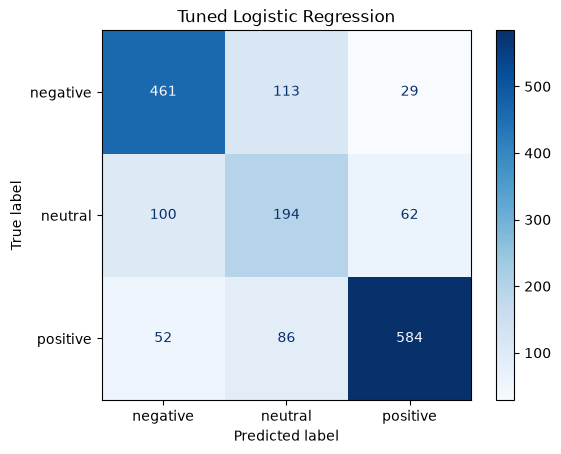

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned,
    labels=["negative", "neutral", "positive"],
    cmap="Blues"
)

plt.title("Tuned Logistic Regression")
plt.show()

In [15]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(
    y_test,
    y_pred_tuned,
    labels=["negative", "neutral", "positive"]
))

[[461 113  29]
 [100 194  62]
 [ 52  86 584]]


In [16]:
sample_reviews = [
    "The sound quality is excellent and I love these headphones.",
    "The battery is terrible and the device keeps crashing.",
    "The sound is good, but the headphones are uncomfortable."
]

cleaned_samples = [clean_text(text) for text in sample_reviews]

predictions = best_model.predict(cleaned_samples)

for review, prediction in zip(sample_reviews, predictions):
    print("Review:", review)
    print("Prediction:", prediction)
    print()

Review: The sound quality is excellent and I love these headphones.
Prediction: positive

Review: The battery is terrible and the device keeps crashing.
Prediction: negative

Review: The sound is good, but the headphones are uncomfortable.
Prediction: neutral



In [17]:
import joblib

joblib.dump(best_model, "sentiment_pipeline.pkl")

['sentiment_pipeline.pkl']